<a href="https://colab.research.google.com/github/sharattt-H/DAV/blob/colab-integration/dav6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:



import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler , MinMaxScaler
from sklearn.decomposition import PCA
print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
data = pd.DataFrame({
    "Study_hours": [2,4,5,7,8,10],
    "Attendence_per":[50,60,65,75,85,95],
    "Assignment_scores":[35,45,55,65,80,95],
    "Total_marks": [38,48,56,68,82,94]

    })
display(data)


,Study_hours,Attendence_per,Assignment_scores,Total_marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
feature = data[["Study_hours","Attendence_per","Assignment_scores"]]
print(feature.min())
print(feature.max())

Study_hours           2
Attendence_per       50
Assignment_scores    35
dtype: int64
Study_hours          10
Attendence_per       95
Assignment_scores    95
dtype: int64


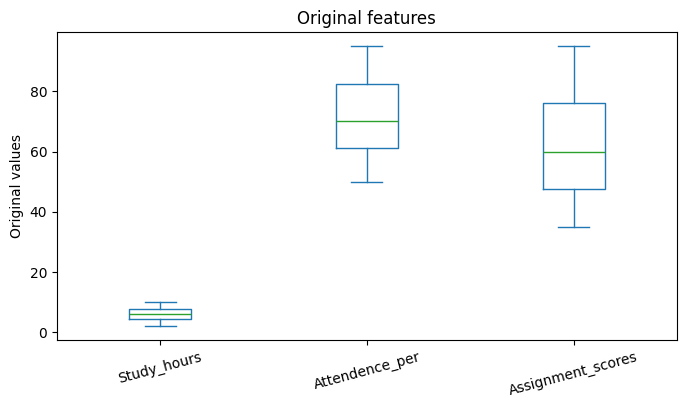

In [ ]:
feature.plot(kind='box',figsize=(8,4))
plt.title("Original Features: Different Scales")
plt.title("Original features")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
normalizer=MinMaxScaler()
normalized_array=normalizer.fit_transform(feature)
normalized_data=pd.DataFrame(normalized_array,columns=feature.columns,index=feature.index)
display(normalized_data.round(3))

,Study_hours,Attendence_per,Assignment_scores
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Minimum after normalization")
print(normalized_data.min())
print("\nMaximum after normalization")
print(normalized_data.max())

Minimum after normalization
Study_hours          0.0
Attendence_per       0.0
Assignment_scores    0.0
dtype: float64

Maximum after normalization
Study_hours          1.0
Attendence_per       1.0
Assignment_scores    1.0
dtype: float64


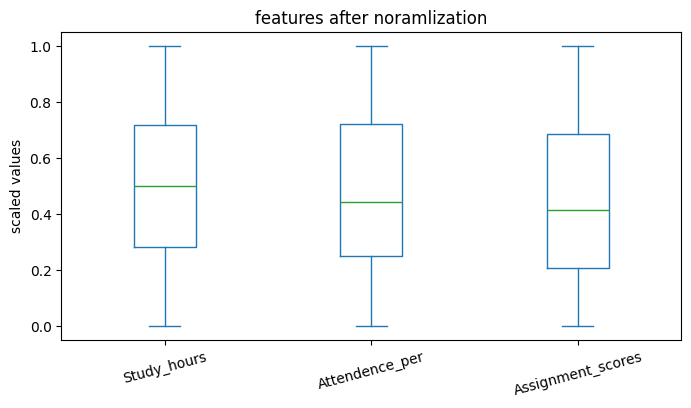

In [ ]:
normalized_data.plot(kind="box", figsize=(8,4))
plt.title("features after noramlization")
plt.ylabel("scaled values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
standardizer=StandardScaler()
standardized_array=standardizer.fit_transform(feature)
standardized_data=pd.DataFrame(standardized_array,columns=feature.columns,index=feature.index)
display(standardized_data.round(3))

,Study_hours,Attendence_per,Assignment_scores
0,-1.512,-1.427,-1.351
1,-0.756,-0.768,-0.859
2,-0.378,-0.439,-0.368
3,0.378,0.220,0.123
4,0.756,0.878,0.859
5,1.512,1.537,1.596


In [ ]:
print("Mean affter standardization")
print(standardized_data.mean().round(6))
print("\nStandard deviation after standardization")
print(standardized_data.std().round(6))

Mean affter standardization
Study_hours          0.0
Attendence_per      -0.0
Assignment_scores    0.0
dtype: float64

Standard deviation after standardization
Study_hours          1.095445
Attendence_per       1.095445
Assignment_scores    1.095445
dtype: float64


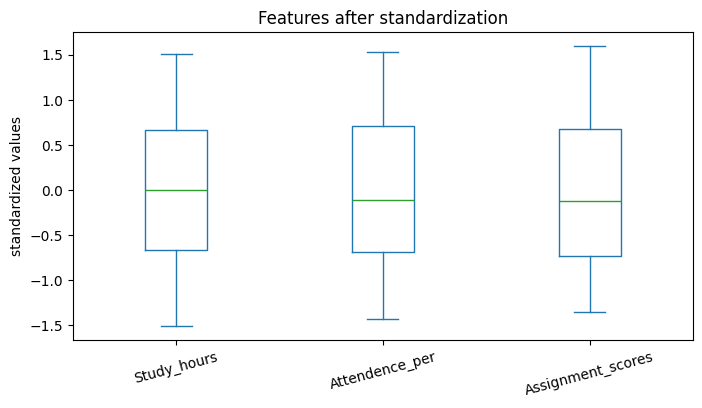

In [ ]:
standardized_data.plot(kind="box",figsize=(8,4))
plt.title("Features after standardization")
plt.ylabel("standardized values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
scaled_features = StandardScaler().fit_transform(feature)
pcs=PCA(n_components=2)
pca_array=pcs.fit_transform(scaled_features)
pca_data=pd.DataFrame(pca_array,columns=["PC1","PC2"],index=feature.index)
display(pca_data.round(3))

,PC1,PC2
0,-2.476,-0.115
1,-1.376,0.069
2,-0.684,-0.001
3,0.416,0.182
4,1.440,-0.078
5,2.682,-0.057


In [ ]:

variance_ratios = pca.explained_variance_ratio_
for component, ratio in zip(["PC1","PC2"],variance_ratios):
    print(f"{component} explains {ratio:2%} of the variance")

total_retained = variance_ratios.sum()
print(f"Total variance retained: {total_retained:2%}")


PC1 explains 99.622543% of the variance
PC2 explains 0.335985% of the variance
Total variance retained: 99.958528%


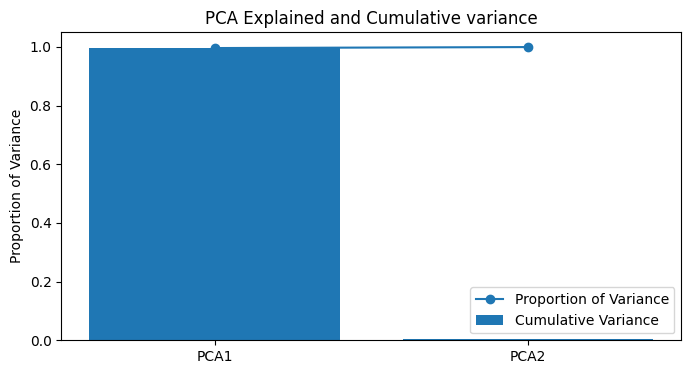

In [ ]:
from numpy import cumulative_prod
component_names = ["PCA1","PCA2"]
cumulative_variance = variance_ratios.cumsum()
plt.figure(figsize=(8,4))
plt.bar(component_names,variance_ratios)
plt.plot(component_names,cumulative_variance,marker="o")
plt.ylim(0,1.05)
plt.ylabel("Proportion of Variance")
plt.title("PCA Explained and Cumulative variance")
plt.legend(["Proportion of Variance","Cumulative Variance"])
plt.show()

In [ ]:
print("Number of original input features:",feature.shape[1])
print("Number of PCA component:",pca_data.shape[1])
print("Original feature shape:",feature.shape)
print("PCA component shape:",pca_data.shape)

Number of original input features: 3
Number of PCA component: 2
Original feature shape: (6, 3)
PCA component shape: (6, 2)
